In [98]:
import pandas as pd
import numpy as np

In [99]:
shots = pd.read_parquet("../data/shots_raw.parquet")
print(shots.shape)

(101227, 122)


### Columns to keep
id
location
minute
period
shot_body_part
shot_outcome
shot_type
shot_technique
type


In [100]:
keep_columns = ['id', 'match_id', 'period', 'location','shot_body_part', 'shot_type', 'shot_technique', 'shot_first_time','shot_outcome', 'under_pressure', 'play_pattern']
shots = shots[keep_columns]

In [101]:
shots = shots[shots["location"].notna()]
shots = shots[shots['period']<5]
shots = shots[shots['shot_type'] != 'Penalty']

In [102]:
shots.shape

(99746, 11)

In [103]:
shots["shot_first_time"] = np.where(shots["shot_first_time"].isna(), False, shots["shot_first_time"])
shots["under_pressure"] = np.where(shots["under_pressure"].isna(), False, shots["under_pressure"])
shots["under_pressure"] = shots["under_pressure"].astype(bool)
shots["shot_first_time"] = shots["shot_first_time"].astype(bool)
shots[["x", "y"]] = pd.DataFrame(shots["location"].tolist(), index=shots.index)
shots['target'] = np.where(shots['shot_outcome'] == 'Goal', 1, 0)

In [104]:
shots = shots.drop_duplicates(subset=['id'], keep='first')
shots.shape

(99746, 14)

In [105]:
shots = shots.drop(columns=['location', 'period', 'shot_outcome'])
shots["shot_first_time"] = shots["shot_first_time"].fillna(False).astype(bool)

In [106]:
print(shots.info())

<class 'pandas.DataFrame'>
Index: 99746 entries, 0 to 101226
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               99746 non-null  str    
 1   match_id         99746 non-null  int64  
 2   shot_body_part   99746 non-null  str    
 3   shot_type        99746 non-null  str    
 4   shot_technique   99746 non-null  str    
 5   shot_first_time  99746 non-null  bool   
 6   under_pressure   99746 non-null  bool   
 7   play_pattern     99746 non-null  str    
 8   x                99746 non-null  float64
 9   y                99746 non-null  float64
 10  target           99746 non-null  int64  
dtypes: bool(2), float64(2), int64(2), str(5)
memory usage: 14.8 MB
None


In [107]:
shots.head()

,id,match_id,shot_body_part,shot_type,shot_technique,shot_first_time,under_pressure,play_pattern,x,y,target
0,452ac1fc-6e97-459f-8819-62bc82078292,3895292,Right Foot,Open Play,Half Volley,False,False,Regular Play,107.0,53.4,0
1,345c34d9-2c2f-4cec-860e-3b3704ebc4f3,3895292,Right Foot,Open Play,Normal,True,False,From Throw In,96.5,39.9,0
2,6627cd42-a35b-4e4e-9fd3-05d3269bca36,3895292,Right Foot,Open Play,Normal,False,False,From Corner,88.2,45.5,0
3,3d1c53e1-4b07-4648-806c-2dc0b2ee5347,3895292,Left Foot,Free Kick,Normal,False,False,From Free Kick,98.5,49.2,0
4,bcdb8320-5e4f-4c64-910a-f4ff7ace5e8b,3895292,Head,Open Play,Normal,False,True,Regular Play,111.2,37.8,0


In [108]:
shots['play_pattern'].value_counts()

play_pattern
Regular Play      33696
From Free Kick    19623
From Throw In     18266
From Corner       16426
From Counter       4711
From Goal Kick     3822
From Keeper        1760
From Kick Off      1205
Other               237
Name: count, dtype: int64

In [109]:
from xg.features import add_features
df = add_features(shots)
df[["distance", "angle", "target"]].describe()

,distance,angle,target
count,99746.000000,99746.000000,99746.000000
mean,19.107230,0.446357,0.102591
std,8.773263,0.280493,0.303425
min,0.400000,0.000000,0.000000
25%,12.081391,0.263825,0.000000
50%,18.413310,0.346886,0.000000
75%,25.317978,0.543717,0.000000
max,92.800862,3.141593,1.000000


In [110]:
df["dist_bin"] = pd.cut(df["distance"], bins=range(0, 45, 3))
df.groupby("dist_bin", observed=True)["target"].agg(["mean", "count"])

,mean,count
dist_bin,,
"(0, 3]",0.723577,246
"(3, 6]",0.422948,2972
"(6, 9]",0.217530,9401
"(9, 12]",0.144204,11983
"(12, 15]",0.136405,12089
"(15, 18]",0.107834,11629
"(18, 21]",0.068391,11098
"(21, 24]",0.046932,10739
"(24, 27]",0.037625,10339


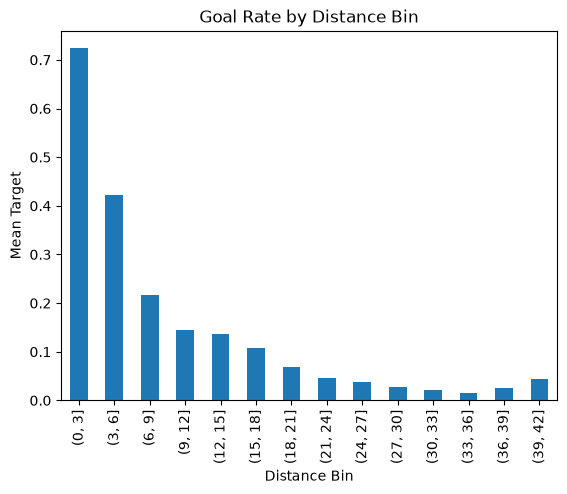

In [111]:
import matplotlib.pyplot as plt
df.groupby("dist_bin", observed=True)["target"].agg(["mean", "count"]).plot(kind="bar", y="mean", legend=False)
plt.xlabel("Distance Bin")
plt.ylabel("Mean Target")
plt.title("Goal Rate by Distance Bin")
plt.show()

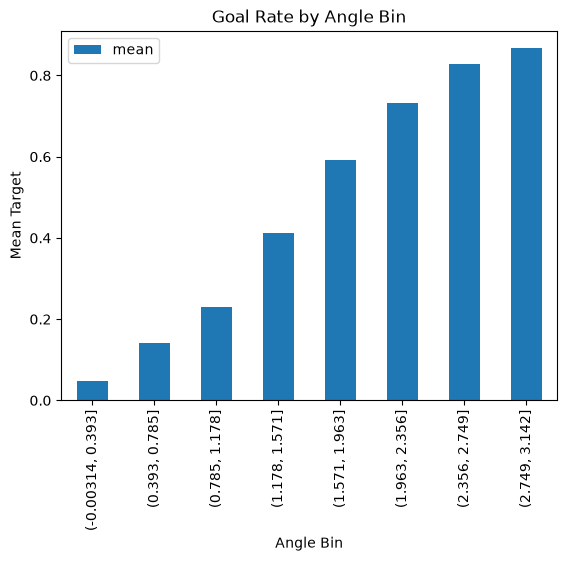

In [112]:
df["angle_bin"] = pd.cut(df["angle"], bins=8)
df.groupby("angle_bin", observed=True)["target"].agg(["mean", "count"]).plot(y="mean", kind="bar")
plt.xlabel("Angle Bin")
plt.ylabel("Mean Target")
plt.title("Goal Rate by Angle Bin")
plt.show()

In [117]:
df = df.drop(columns=['dist_bin', 'angle_bin'])

In [118]:
df.head()

,id,match_id,shot_body_part,shot_type,shot_technique,shot_first_time,under_pressure,play_pattern,x,y,target,distance,angle
0,452ac1fc-6e97-459f-8819-62bc82078292,3895292,Right Foot,Open Play,Half Volley,False,False,Regular Play,107.0,53.4,0,18.669762,0.303090
1,345c34d9-2c2f-4cec-860e-3b3704ebc4f3,3895292,Right Foot,Open Play,Normal,True,False,From Throw In,96.5,39.9,0,23.500213,0.337188
2,6627cd42-a35b-4e4e-9fd3-05d3269bca36,3895292,Right Foot,Open Play,Normal,False,False,From Corner,88.2,45.5,0,32.272124,0.243168
3,3d1c53e1-4b07-4648-806c-2dc0b2ee5347,3895292,Left Foot,Free Kick,Normal,False,False,From Free Kick,98.5,49.2,0,23.385679,0.313313
4,bcdb8320-5e4f-4c64-910a-f4ff7ace5e8b,3895292,Head,Open Play,Normal,False,True,Regular Play,111.2,37.8,0,9.070832,0.815532


In [119]:
df.columns.to_list()

['id',
 'match_id',
 'shot_body_part',
 'shot_type',
 'shot_technique',
 'shot_first_time',
 'under_pressure',
 'play_pattern',
 'x',
 'y',
 'target',
 'distance',
 'angle']

In [121]:
df.to_parquet("../data/shots_curated.parquet")